# 06-03 - Words about Pictures

You compare pictures with captions in a model that learned both at once, run it on the test chips on your laptop, and read what a vision-language model answered about the same chips.

We start with CLIP's answer over the window, compute its numbers for the 320 test chips, read a matrix of chips against captions, fit a head, and let CLIP name the masks of 06-01. Then the vision-language model: four chips questioned, the class question scored. At the end you change the captions.

Before you run anything, choose *File*, then *Save As*, and give the copy a name with `-mywork` in it, so that the next pull never collides with your work.

In [1]:
import json

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import fm_tools as fm

plt.rcParams["figure.dpi"] = 72

scene = fm.load_scene("data/scene.json")
reference = json.load(open("data/ground_truth.json"))["p06"]
torch_ok = fm.torch_available()
ready = {name: torch_ok and fm.model_ready(name) for name in ("sam2", "clip")}
print(f"the window of {scene['window']['date']}: {scene['window']['pixels']:,} pixels a side at "
      f"{scene['window']['resolution_m']} m, {scene['blocks']['n']} blocks, "
      f"{scene['chips']['tiled']['total']:,} chips; the deep learning library is "
      f"{'ready' if torch_ok else 'missing, so the cells that need it are skipped'}; the open models are "
      f"{'ready' if all(ready.values()) else 'not loadable here, so the cells that run them are skipped'}")

the window of 2023-08-20: 10,240 pixels a side at 0.3 m, 25 blocks, 1,600 chips; the deep learning library is ready; the open models are ready


## A caption over the window

The cell reads CLIP's shipped numbers for all 1,600 chips, the probability of the building caption on each, and draws it beside the chips' labels.

the captions: 'a satellite photo of buildings' against 'a satellite photo of trees and fields'
right on 83.1% of the 320 test chips   reference 83.1%


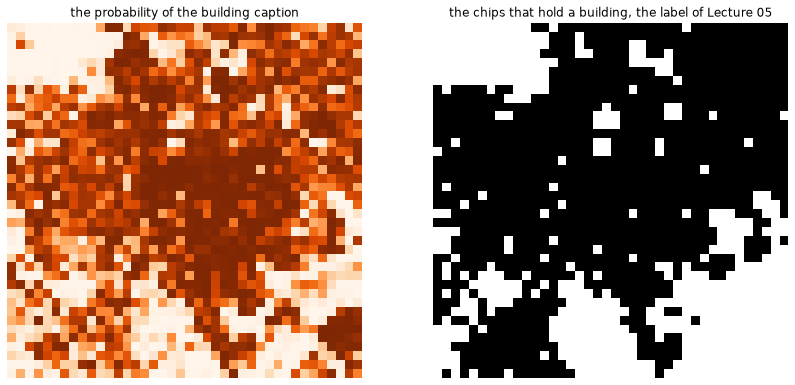

In [2]:
c = fm.read_npz("data/clip_chips.npz")
sets, name = json.loads(c["caption_sets"]), scene["captions"]["chosen"]
test = c["split"] == 2
grid, labels_grid = np.zeros((40, 40)), np.zeros((40, 40))
grid[c["row"] // 256, c["col"] // 256] = c[f"prob_{name}"]
labels_grid[c["row"] // 256, c["col"] // 256] = c["label"]
acc = ((c[f"prob_{name}"][test] >= 0.5) == c["label"][test]).mean()
print(f"the captions: {sets[name][0]!r} against {sets[name][1]!r}")
print(f"right on {acc:.1%} of the 320 test chips   reference {reference['clip']['zero_shot'][name]:.1%}")
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
fm.show_image(axes[0], grid, "the probability of the building caption", cmap="Oranges", vmin=0, vmax=1)
fm.show_image(axes[1], labels_grid, "the chips that hold a building, the label of Lecture 05", cmap="Greys")

CLIP learned from 400 million pictures with their captions to put a picture and its caption close together as vectors. Give it a chip and two captions and it says which fits better, with no training on Princeton and no label. Over the window the probability of the building caption rises on the streets of houses and falls on the lake and the woods. Scored against the label of Lecture 05, the answer is right four times in five; calling everything a building is right three times in four.

## The 320 test chips

The cell cuts the 320 test chips from the five shipped test blocks, in the order of the chip table, and shows the first eight.

320 chips of 256 pixels from blocks [7, 10, 13, 18, 20], 245 with a building


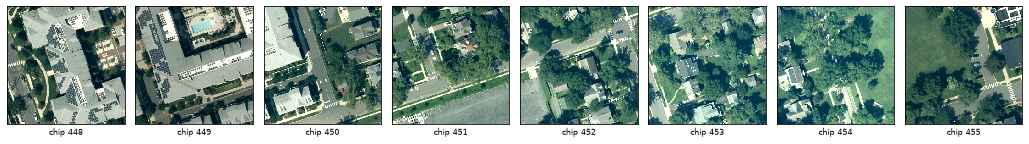

In [3]:
chips = fm.chip_table("data/chips.csv")
test_blocks = scene["test_blocks"]
imgs = {b: fm.read_raster(f"data/block_{b}.tif")[0] for b in test_blocks}
starts = {b: ((b // 5) * 2048, (b % 5) * 2048) for b in test_blocks}
test_rows = chips[chips["split"] == "test"]
pieces = [fm.cut_chips(imgs[r.block], [r.row], [r.col], starts[r.block]) for r in test_rows.itertuples()]
images = np.concatenate(pieces)
print(f"{len(images)} chips of {images.shape[-1]} pixels from blocks {test_blocks}, "
      f"{int(test_rows['label'].sum())} with a building")
fig = fm.show_chips(images[:8], titles=[f"chip {i}" for i in test_rows.index[:8]], ncols=8, size=1.8)

The 320 test chips of Lecture 05 are the 64 tiles of each of the five test blocks, so the blocks the kit ships are the chips too, cut here in the order of the table. These are the pictures CLIP saw and the vision-language model was asked about, 77 m of ground each at 30 cm. The lecture's numbers were computed on these same pixels, and the next cell computes them again on yours.

## Through CLIP on your laptop

The cell runs the 320 chips through CLIP on your processor, scores the captions, and compares the result with the shipped numbers.

In [4]:
if torch_ok and ready['clip']:
    clip = fm.load_clip()
    feats = fm.clip_image_features(clip, images)
    text = fm.clip_text_features(clip, sets[name])
    probs = fm.zero_shot(feats, text, fm.logit_scale(clip))
    live = ((probs[:, 0] >= 0.5) == c["label"][test]).mean()
    rl = reference["clip"].get("live", {})
    print(f"{len(images)} chips through CLIP on this processor: {live:.1%} right   reference "
          f"{rl.get('accuracy', float('nan')):.1%}; the lecture's run on a graphics chip {acc:.1%}")
    diff = np.abs(feats - c["features"][test].astype("float32")).max()
    print(f"the largest difference between your 512 numbers and the shipped ones: {diff:.4f}")
else:
    print(fm.NO_TORCH if not torch_ok else fm.NO_MODEL)

320 chips through CLIP on this processor: 83.1% right   reference 83.1%; the lecture's run on a graphics chip 83.1%
the largest difference between your 512 numbers and the shipped ones: 0.0002


Nothing changes between the graphics chip that computed the shipped numbers and your processor except the time: 512 numbers per chip, the same to the third decimal, the same answers. The model is deterministic, and the kit ships the numbers only so that the next sections run without the weights. Half a minute on a laptop for 320 chips is the price of a vision transformer at 224 pixels.

## Eight chips against eight captions

The cell takes the four test chips CLIP is surest hold houses and the four it is surest do not, and prints their cosines with eight captions.

the eight chips: [855, 492, 507, 448, 1338, 1329, 1198, 1190]   reference [855, 492, 507, 448, 1338, 1329, 1198, 1190]
zero-shot by caption set: satellite 83.1%, aerial 87.8%, plain 64.1%, long 82.5%


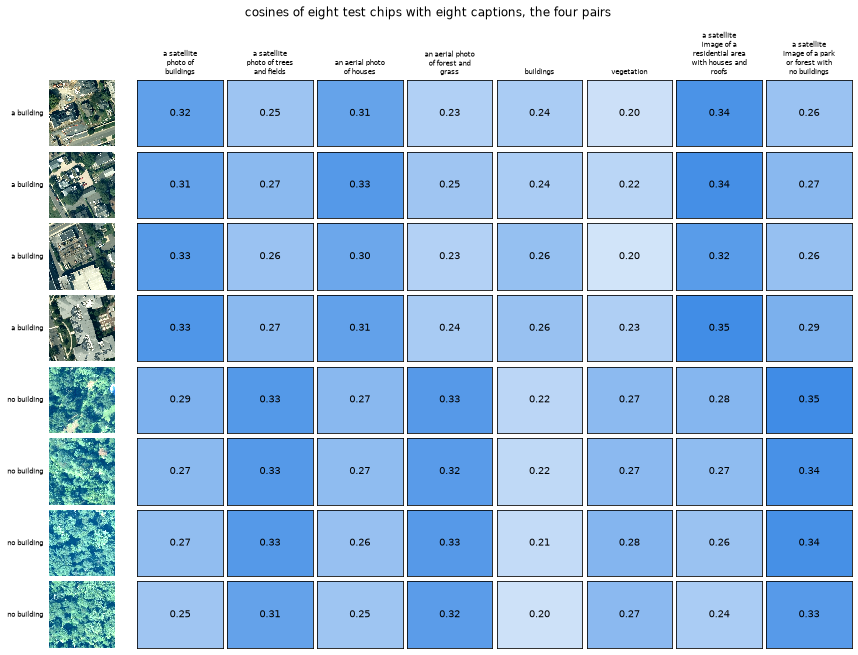

In [5]:
order = np.flatnonzero(test)[np.argsort(-c["prob_aerial"][test])]
eight = [int(j) for j in list(order[:4]) + list(order[-4:])]
captions = [cap for s in ("satellite", "aerial", "plain", "long") for cap in sets[s]]
text_all = np.concatenate([c[f"text_{s}"] for s in ("satellite", "aerial", "plain", "long")])
cos = c["features"][eight].astype("float32") @ text_all.T
print(f"the eight chips: {eight}   reference {reference['clip']['matrix_chips']}")
print("zero-shot by caption set: " + ", ".join(f"{s} {reference['clip']['zero_shot'][s]:.1%}" for s in sets))
pos = {int(j): k for k, j in enumerate(np.flatnonzero(test))}
names = ["a building" if c["label"][j] else "no building" for j in eight]
fig = fm.show_matrix([images[pos[j]] for j in eight], captions, cos, vmin=0.15, vmax=0.35, rows=names,
                     title="cosines of eight test chips with eight captions, the four pairs")

The matrix is the model's whole answer. Every cell is the cosine between a chip's 512 numbers and a caption's 512 numbers, all between 0.15 and 0.35, and the zero-shot answer is only the softmax over a pair of columns. Read the rows: the chips with houses lean to the first caption of each pair, the chips without to the second, and the margins are small. Read the pairs: the aerial captions separate the rows best and the bare words worst, which is why the caption belongs on the poster.

## A head on CLIP's numbers

The cell fits a logistic head on CLIP's 512 numbers of the training chips, as 05-01 did on the ImageNet network's, and scores it on the test chips.

In [6]:
labels, train = c["label"].astype(int), c["split"] == 0
feats_all = c["features"].astype("float32")
head = fm.fit_head(feats_all, labels, train, C=scene["captions"]["head_C"])
head_acc = fm.head_accuracy(head, feats_all, labels, np.flatnonzero(test))
rc = reference["clip"]
print(f"a head on CLIP's numbers, test chips {head_acc:.1%}   reference {rc['head']['accuracy']:.1%}")
print(f"the same head on the ImageNet network's numbers in 05-01 "
      f"{rc['lecture']['resnet_frozen_fitted_head']:.1%}; the fine-tuned network "
      f"{rc['lecture']['resnet_finetuned']:.1%}; a building everywhere {rc['baseline']:.1%}")

a head on CLIP's numbers, test chips 93.1%   reference 93.1%
the same head on the ImageNet network's numbers in 05-01 90.0%; the fine-tuned network 91.9%; a building everywhere 76.6%


A zero-shot answer and a fitted head are the two ways to use the same numbers. With 1,024 labelled chips a head of 513 weights on CLIP's numbers beats the zero-shot caption by ten points and the fine-tuned network of Lecture 05 by one. CLIP's numbers carry more about Princeton's roofs than the ImageNet network's did, although neither model saw an aerial photograph with a label in training. The penalty is the one the lecture chose on the validation chips, read from the scene file.

## A mask has no class

The cell reads the lecture's naming of the 171 everything masks of 06-01, each shown to CLIP with four captions, and draws them in the colour of their name.

building 96, trees 41, road or lot 9, lawn or field 25   reference 96, 41, 9, 25
masks named building against the roof: recall 0.639, precision 0.783   reference 0.639, 0.7832


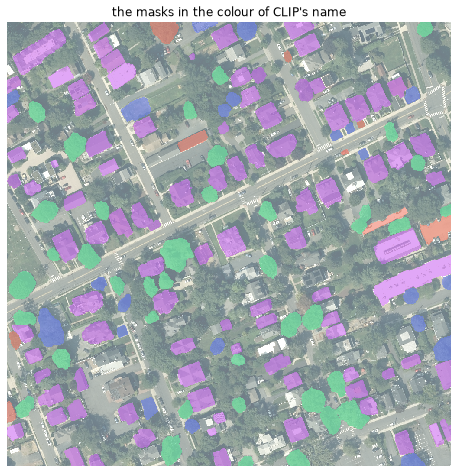

In [7]:
z = fm.read_npz("data/prompts_7.npz")
every, named, nm = z["everything"], z["named_label"], reference["everything"]["named"]
counts = {nm["short"][j]: int((named == j).sum()) for j in range(4)}
building_masks = np.isin(every, np.flatnonzero(named == 0) + 1)
pm = fm.pixel_metrics(fm.confusion(building_masks, z["footprints"] > 0))
print(", ".join(f"{k} {v}" for k, v in counts.items())
      + "   reference " + ", ".join(str(v) for v in nm["counts"].values()))
print(f"masks named building against the roof: recall {pm['recall']:.3f}, precision {pm['precision']:.3f}"
      f"   reference {nm['building_masks']['recall']}, {nm['building_masks']['precision']}")
by_name = np.where(every > 0, named[np.maximum(every, 1) - 1] + 1, 0)
fig, ax = plt.subplots(figsize=(8, 8))
fm.show_instances(ax, fm.stretch(z["crop"]), by_name, "the masks in the colour of CLIP's name", alpha=0.6)

A segment-anything model gives masks and CLIP gives names, and together they make the label machine the lecture described. Every mask of 06-01's crop was cut out with a small margin and shown to CLIP with four captions; the winning caption is the mask's name. Ninety-six masks became buildings, and they cover two thirds of the roof pixels with a false alarm in one pixel of five. The errors are the ones you would guess: a driveway named building, a dark roof named trees.

## A model that reads and sees

The cell reads the answers the lecture's vision-language model gave to four test chips, a caption, a count, a yes or no and the class, under the chips.

Qwen/Qwen3-VL-2B-Instruct, asked 'Describe this aerial photograph in one sentence.', 'How many buildings are in this aerial photograph? Answer with a single number.', 'Is there a parking lot in this aerial photograph? Answer yes or no.' and the class question
chip 647: An aerial view of a residential neighborhood with several swimming pools, surrounded by lush green trees and houses. | count 5 | parking no | tree cover
chip 470: An aerial view of a residential neighborhood with houses, trees, and a paved road. | count 10 | parking yes | tree cover
chip 833: An aerial view of a residential neighborhood with a large, multi-story building and a parking lot, surrounded by trees and streets with crosswalks. | count 5 | parking yes | tree cover
chip 1153: An aerial view of a large, multi-building complex with a flat roof, surrounded by smaller structures and greenery. | count 12 | parking yes | built-up


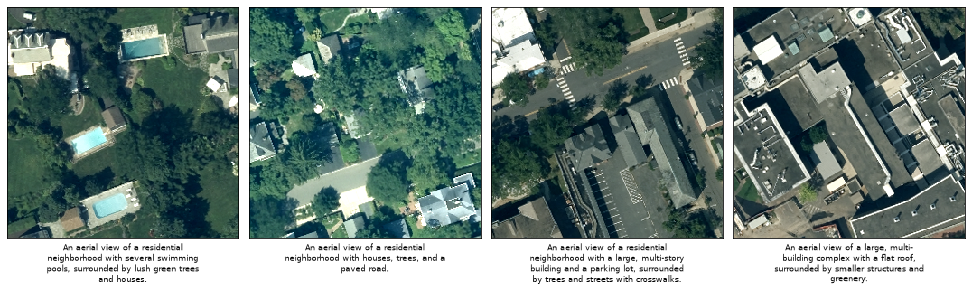

In [8]:
answers = fm.read_answers("data/vlm_answers.json")
four, qs = reference["vlm"]["four"], scene["questions"]
print(f"{answers['_run']['model']}, asked {qs['caption_prompt']!r}, {qs['count_question']!r}, "
      f"{qs['parking_question']!r} and the class question")
for f in four:
    print(f"chip {f['chip']}: {f['caption']} | count {f['count']} | parking {f['parking']} | {f['cls']}")
fig = fm.show_chips([images[pos[f["chip"]]] for f in four], titles=[f["caption"] for f in four],
                    ncols=4, size=3.4, wrap=40)

A vision-language model is a language model with eyes: a vision transformer turns the chip into a few hundred tokens, a projector maps them into the language model's space, and the language model continues the text. Ask it anything. The captions are fluent and mostly right, the counts are numbers it produced rather than measured, and the yes or no answers are confident either way. The lecture's model answered 352 questions in eight minutes on a graphics chip; the kit ships every answer with the model's name and revision.

## The class question on 320 chips

The cell scores the model's answer to the class question on every test chip against the WorldCover class under the chip, as an error matrix.

the model agrees with WorldCover on 67.8% of 320 chips, the majority class 63.7%   reference 67.8%


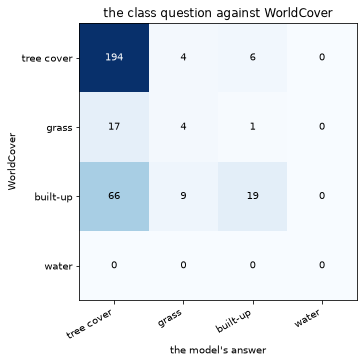

In [9]:
labels10, lt, _, _ = fm.read_raster("data/labels_2021.tif")
wt = fm.window_transform(scene)
rows = fm.answer_rows(answers, "class_")
y_true = np.array([fm.chip_class(labels10, lt, wt, int(chips.row[i]), int(chips.col[i])) for i, _ in rows])
y_model = np.array([fm.parse_class(a) for _, a in rows])
keep = y_true > 0
matrix, agree = fm.error_matrix(y_true[keep], y_model[keep]), (y_true[keep] == y_model[keep]).mean()
rv = reference["vlm"]
print(f"the model agrees with WorldCover on {agree:.1%} of {int(keep.sum())} chips, the majority class "
      f"{rv['majority']:.1%}   reference {rv['agreement']:.1%}")
fig, ax = plt.subplots(figsize=(6, 5))
fm.show_error_matrix(ax, matrix, rv["class_order"], "the class question against WorldCover")

The error matrix of Lecture 04 holds for a model that answers in words. The reference is the WorldCover class under the chip, sampled at nine points, and the answer is parsed for the first class word it contains. The model beats the majority class by four points, and the matrix shows where: it calls most chips tree cover, which most of them are, and misses two thirds of the built-up chips. An answer in words is still a classifier, and a classifier gets an error matrix and a baseline.

## Counting buildings

The cell holds the model's count of buildings on twenty chips against the number of footprints inside each chip, and draws one against the other.

20 chips: mean error 1.65 buildings, largest 8, exact on 4   reference 1.65, 8, 4


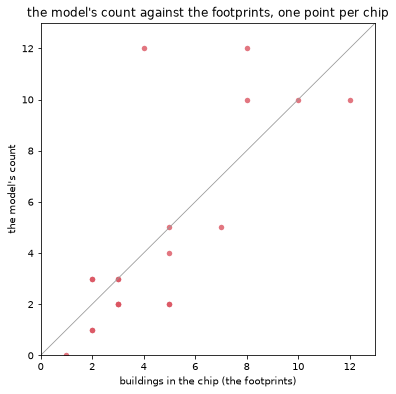

In [10]:
ids = {b: fm.footprint_ids(b) for b in test_blocks}
counts = []
for i, a in fm.answer_rows(answers, "count_"):
    b = int(chips.block[i])
    r0, c0 = int(chips.row[i]) - starts[b][0], int(chips.col[i]) - starts[b][1]
    counts.append((fm.count_footprints(ids[b][r0:r0 + 256, c0:c0 + 256]), fm.parse_count(a)))
ref_n, model_n = np.array([r[0] for r in counts]), np.array([r[1] for r in counts])
errs, rv = np.abs(model_n - ref_n), reference["vlm"]["counts"]
print(f"{len(counts)} chips: mean error {errs.mean():.2f} buildings, largest {errs.max()}, exact on "
      f"{int((errs == 0).sum())}   reference {rv['mean_abs_error']}, {rv['max_abs_error']}, {rv['exact']}")
fig, ax = plt.subplots(figsize=(6, 6))
fm.show_counts(ax, ref_n, model_n, "the model's count against the footprints, one point per chip")

Counting is where these models fail most honestly. The reference is the number of footprints with at least a hundred pixels inside the chip, and the model's answer is the number in its sentence. It is right on a few chips, off by one or two on most, and off by eight on one, where it counted every roof plane of a large building. A number a language model produces is a plausible number, not a measurement, which is why the lecture counted with a segmenter.

## The small model, shipped and live

The cell scores the shipped answers of the small vision-language model, and holds the switched-off recipe that would ask it a question on your laptop after a download.

In [11]:
LIVE = False
small = fm.read_answers("data/vlm_answers_small.json")
y_small = np.array([fm.parse_class(a) for _, a in fm.answer_rows(small, "class_")])
print(f"the small model's answers agree with WorldCover on {(y_true[keep] == y_small[keep]).mean():.1%}"
      f"   reference {reference['vlm']['small']['agreement']:.1%}, below the majority class")
if LIVE:
    from transformers import AutoModelForImageTextToText, AutoProcessor
    model = AutoModelForImageTextToText.from_pretrained(scene["models"]["vlm_small"]["id"]).eval()
    processor = AutoProcessor.from_pretrained(scene["models"]["vlm_small"]["id"])
    print("the small model is loaded; the paragraph below says how to ask it about images[0]")
else:
    print("the live lane is off; the shipped answers came from this recipe on the course's laptop")

the small model's answers agree with WorldCover on 61.3%   reference 61.3%, below the majority class
the live lane is off; the shipped answers came from this recipe on the course's laptop


To ask the small model yourself, set the switch to True on a machine with a connection and a gigabyte to spare. Build the conversation with the processor's chat template, one image and one text turn, hand the processor the picture and the prompt, and call generate with a few dozen new tokens. The shipped answers came from exactly this, and they are worse than the lecture's model's on every question. A project that uses such answers reports which model, which revision and which question.

## Your turn

The captions of the satellite set called the chips satellite photos, which they are not. Try the aerial set, whose captions say aerial photo and houses, on the same 320 test chips. Run the cell as it is, then change the marked value and run it again.

How much did the wording buy, and what does that say about reporting a zero-shot number without its caption? Write your answer in one or two sentences. The answer comes in Friday's post, not in the kit.

In [12]:
CAPTIONS = "satellite"  # change me: "aerial"
right = ((c[f"prob_{CAPTIONS}"][test] >= 0.5) == c["label"][test]).mean()
print(f"the {CAPTIONS} captions {sets[CAPTIONS]}: {right:.1%} of the test chips right")

the satellite captions ['a satellite photo of buildings', 'a satellite photo of trees and fields']: 83.1% of the test chips right


## Check your understanding

1. CLIP's zero-shot answer and a head on CLIP's numbers use the same 512 numbers. What does the head add, and what does it cost?
2. The cosines in the matrix all sit between 0.15 and 0.35. Why does a softmax with a large scale still give a confident answer, and why is that confidence not an accuracy?
3. The vision-language model beat the majority class by four points and the small model fell below it. What would you report, and against which baseline?
4. The model counted eight buildings too many on one chip. Name two reasons a language model's count is not a measurement.

## Where we are

You have run CLIP on the test chips on your own processor and matched the shipped numbers, read the matrix of chips against captions, fitted a head that beats the fine-tuned network, let CLIP name the masks of 06-01, and scored a vision-language model's words against the labels of Lecture 04. You now know what a caption buys, what a question returns, and how to score both. In 06-04 every place in the town becomes a vector, and a map is made from a handful of labelled cells.

## Further resources

Nothing in this course requires anything below.

- GeoAI with Python, chapter 15 on vision-language models, Qiusheng Wu, 2026, https://geoai.gishub.org
- Learning Transferable Visual Models From Natural Language Supervision, Alec Radford and colleagues, ICML 2021, https://arxiv.org/abs/2103.00020
- Qwen3-VL technical report, the Qwen team, 2025, https://arxiv.org/abs/2511.21631
- SmolVLM: Redefining small and efficient multimodal models, Andrés Marafioti and colleagues, 2025, https://arxiv.org/abs/2504.05299

The masks, numbers and this kit are the course's own work, published under CC BY 4.0. The imagery is NAIP 2023 of the USDA, public domain, read from the Planetary Computer. SAM 2.1 (Meta) is released under the Apache 2.0 licence, CLIP ViT-B/16 (OpenAI) under the MIT licence. The AlphaEarth Foundations Satellite Embedding dataset is produced by Google and Google DeepMind, licensed CC BY 4.0; the labels are ESA WorldCover 2021, CC BY 4.0. The answers are those of Qwen3-VL-2B-Instruct (Alibaba, Apache 2.0) and SmolVLM-500M-Instruct (Hugging Face, Apache 2.0), run as published.